# Python API example (load a production run)

Loads the model + link table produced by a genome-wide, batch-corrected `run_genomewide.sh` run (multiDGD training + gene2peak perturbation over all genes; a multi-hour GPU job) and visualizes them — no retraining. Set the paths below to your `run_genomewide.sh` output. The heavy train/perturbation steps appear as commented reference cells with rough timings.

In [1]:
from multidgd_e2g import io, MultiDGDAdapter, compute_cell_deltas
import pandas as pd, numpy as np

# --- edit these to your run_genomewide.sh output (genome-wide, batch-corrected) ---
EXPORT_DIR = "path/to/genomewide_export"
MODEL_DIR  = "path/to/run/model"
MODEL_NAME = "dgd_cd14_e2g"
LINKS      = "path/to/run/links.tsv"
GTF        = "path/to/genes.gtf"   # genome-wide gene models (GTF) for the locus/heatmap TSS   # genome-wide gene models (GTF) for the locus/heatmap TSS

## Step 1 — Load the export

`read_export` rebuilds the AnnData the run trained on (genome-wide; the .mtx is large, so this takes a moment). `assign_train_val_split` reproduces the training split (seed 0) so the loaded per-cell representations line up.

In [2]:
adata, genes, peaks, pairs = io.read_export(EXPORT_DIR)
io.assign_train_val_split(adata)
print(f"{adata.n_obs} cells | {len(genes)} genes | {len(peaks)} peaks | {len(pairs)} candidate pairs")

5486 cells | 19624 genes | 108533 peaks | 697064 candidate pairs


## Step 2 — Load the trained model

Training is done by `run_genomewide.sh` (multi-hour GPU); here we load the saved checkpoint. `learn_test_representations` (a few minutes) is needed only for the per-cell heatmap in Step 8.

In [3]:
# --- produced by run_genomewide.sh (training ~hours on GPU); shown for reference ---
# model = MultiDGDAdapter.train(adata, MODEL_DIR + '/', MODEL_NAME, latent_dim=20,
#                               n_components=None, n_epochs=500)
model = MultiDGDAdapter.load(adata, MODEL_DIR.rstrip('/') + '/', MODEL_NAME)
model.learn_test_representations(adata, n_epochs=20)

Covariate model initialized as:

        Gaussian_mix_compture:
            Dimensionality: 2
            Number of components: 2
        


#######################
Training status
#######################
True


making potential reps
   all potential reps:  torch.Size([2, 22])
calculating losses for each new sample and potential reps


training selected reps for  20  epochs


Training:   0%|          | 0/20 [00:00<?, ?epochs/s]

...

Training:  90%|█████████ | 18/20 [01:29<00:09,  4.72s/epochs, loss=0.294, reconstruction_loss=0.293]

Training:  95%|█████████▌| 19/20 [01:29<00:04,  4.72s/epochs, loss=0.294, reconstruction_loss=0.293]

Training:  95%|█████████▌| 19/20 [01:34<00:04,  4.72s/epochs, loss=0.294, reconstruction_loss=0.293]

Training: 100%|██████████| 20/20 [01:34<00:00,  4.71s/epochs, loss=0.294, reconstruction_loss=0.293]

Training: 100%|██████████| 20/20 [01:34<00:00,  4.73s/epochs, loss=0.294, reconstruction_loss=0.293]

## Model diagnostics (optional)

`plot_latent_space()` (latent PCA + GMM) loads from the checkpoint. `plot_history()` is only available right after training (multiDGD does not persist it) — see `run_genomewide.sh`.

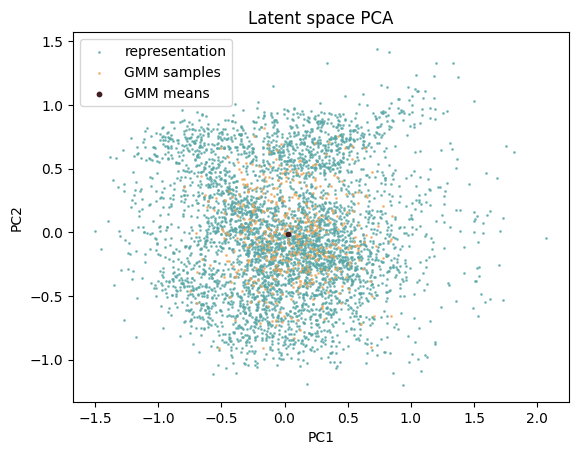

In [4]:
model.model.plot_latent_space()

### Covariate (sample) latent

`get_covariate_representation()` returns the correction latent; coloured by sample it shows the batch structure the model corrects for.

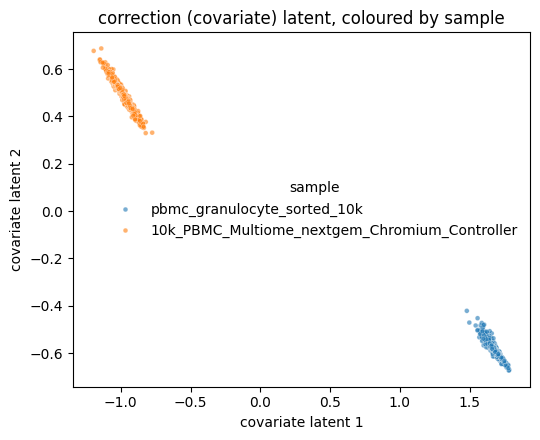

In [5]:
import seaborn as sns, matplotlib.pyplot as plt

cov = model.model.get_covariate_representation(split='train')
train_mask = adata.obs['train_val_test'].values == 'train'
sample = adata.obs.loc[train_mask, 'covariate_sample'].values

fig, ax = plt.subplots(figsize=(5.5, 4.5))
if cov.shape[1] >= 2:
    sns.scatterplot(x=cov[:, 0], y=cov[:, 1], hue=sample, s=12, alpha=0.6, ax=ax)
    ax.set_xlabel('covariate latent 1'); ax.set_ylabel('covariate latent 2')
else:
    y = np.random.default_rng(0).normal(0, 0.02, size=cov.shape[0])
    sns.scatterplot(x=cov[:, 0], y=y, hue=sample, s=12, alpha=0.6, ax=ax)
    ax.set_xlabel('covariate latent'); ax.set_yticks([])
ax.set_title('correction (covariate) latent, coloured by sample')
ax.legend(title='sample', frameon=False)
plt.tight_layout(); plt.show()

## Step 3 — Perturbation + scoring (done by run_genomewide.sh)

The genome-wide perturbation over all genes and the scoring are the heavy GPU steps; `run_genomewide.sh` runs them and writes the link table we load in Step 4. Shown here as reference. `build_groups` (fast) is still run because Step 8's heatmap needs `silenced_index`.

In [6]:
gene_row = {g: i for i, g in enumerate(genes)}
peak_col = {p: i for i, p in enumerate(peaks)}
groups, silenced_index, resp_index = io.build_groups(pairs, gene_row, peak_col, 'gene2peak')

# --- heavy: produced by run_genomewide.sh (perturbation over all genes ~hours on GPU) ---
# from multidgd_e2g import compute_deltas, score_from_deltas, records_to_p2g
# D, kept, p0, resp_names = compute_deltas(model, groups, silenced_index, resp_index,
#                                          'gene2peak', cell_batch=8192)
# records = score_from_deltas(D, kept, p0, groups, resp_index, 'gene2peak', match_bg=False)
# records_to_p2g(records).to_csv(LINKS, sep='\t', index=False)

## Step 4 — Load the link table

In [7]:
from multidgd_e2g import bh_fdr
df = pd.read_csv(LINKS, sep='\t')
# recompute BH-FDR from the (correct) p-values so significance is right regardless of the file
df['fdr'] = bh_fdr(df['pvalue'].values)
df['twosided_fdr'] = bh_fdr(df['twosided_pvalue'].values)
print(f'{len(df)} links loaded')
df.sort_values('score', ascending=False).head(10)

595594 links loaded


,peak,peak_chr,peak_start,peak_end,gene,score,delta,zscore,pvalue,fdr,twosided_pvalue,twosided_fdr,link_dir
437786,chr19-54189073-54191521,chr19,54189073,54191521,RPS9,281.170145,-0.000012,35.858580,6.758572e-282,4.025365e-276,1.351714e-281,1.006341e-276,1
356674,chr19-54189073-54191521,chr19,54189073,54191521,OSCAR,128.821130,-0.000003,24.187399,1.509629e-129,4.495630e-124,3.019258e-129,2.809769e-125,1
43836,chr12-89707614-89710248,chr12,89707614,89710248,ATP2B1,123.128682,-0.000008,23.640245,7.435628e-124,1.476205e-118,1.487126e-123,1.247497e-119,1
147678,chr5-172770460-172772767,chr5,172770460,172772767,DUSP1,90.685657,-0.000011,20.242642,2.062259e-91,3.070673e-86,4.124519e-91,1.861014e-87,1
535737,chr13-45339885-45341901,chr13,45339885,45341901,TPT1,79.644837,-0.000002,18.948645,2.265495e-80,2.698631e-75,4.530990e-80,1.490956e-76,1
188086,chr11-61961837-61964233,chr11,61961837,61964233,FTH1,73.741027,-0.000007,18.219253,1.815401e-74,1.802070e-69,3.630802e-74,1.010506e-70,1
329678,chr7-106283891-106285700,chr7,106283891,106285700,NAMPT,72.684869,-0.000008,18.085685,2.066004e-73,1.757856e-68,4.132007e-73,1.098660e-69,1
595227,chr5-61330563-61333840,chr5,61330563,61333840,ZSWIM6,71.679304,-0.000007,17.957598,2.092649e-72,1.557962e-67,4.185299e-72,1.088532e-68,1
259220,chr19-16324171-16325711,chr19,16324171,16325711,KLF2,58.213113,-0.000008,16.145357,6.121915e-59,4.051307e-54,1.224383e-58,1.899050e-55,1
88309,chr1-207320730-207322399,chr1,207320730,207322399,CD55,55.771263,-0.000005,15.794651,1.693311e-56,1.008526e-51,3.386621e-56,4.883901e-53,1


## Step 5 — Summary

Significant links by FDR, one-sided vs two-sided, split by direction (`link_dir`: +1 activating / -1 repressive).

In [8]:
PTHR = 0.05
for name, pcol, fcol in [('one-sided', 'pvalue', 'fdr'), ('two-sided', 'twosided_pvalue', 'twosided_fdr')]:
    fsig = df[fcol] < 0.1
    print(f'{name:10s}: nominal p<0.05 = {int((df[pcol]<PTHR).sum()):6d}   FDR<0.1 = {int(fsig.sum()):6d}   '
          f'(FDR: +{int((fsig & (df.link_dir>0)).sum())} activating, -{int((fsig & (df.link_dir<0)).sum())} repressive)')
df[['pvalue', 'fdr', 'twosided_pvalue', 'twosided_fdr']].describe().loc[['min', '50%', 'max']]

one-sided : nominal p<0.05 =   2372   FDR<0.1 =    873   (FDR: +873 activating, -0 repressive)
two-sided : nominal p<0.05 =  34090   FDR<0.1 =  23311   (FDR: +1203 activating, -22108 repressive)


,pvalue,fdr,twosided_pvalue,twosided_fdr
min,6.758572e-282,4.025365e-276,0.000000,0.000000
50%,4.287692e-01,6.259706e-01,0.805487,0.999992
max,1.000000e+00,1.000000e+00,1.000000,1.000000


## Step 6 — Volcano: significance by p-value vs FDR

Same `delta` axis in every panel (negative = activating, positive = repressive). Columns: the one-sided (activating-tail) vs two-sided test. Rows: points called significant by **nominal p<0.05** (uncorrected) vs **FDR<0.1** (multiple-testing corrected). The one-sided test can only flag the negative-`delta` side; the large positive-`delta` cluster under two-sided is mostly the softmax-renormalization artifact.

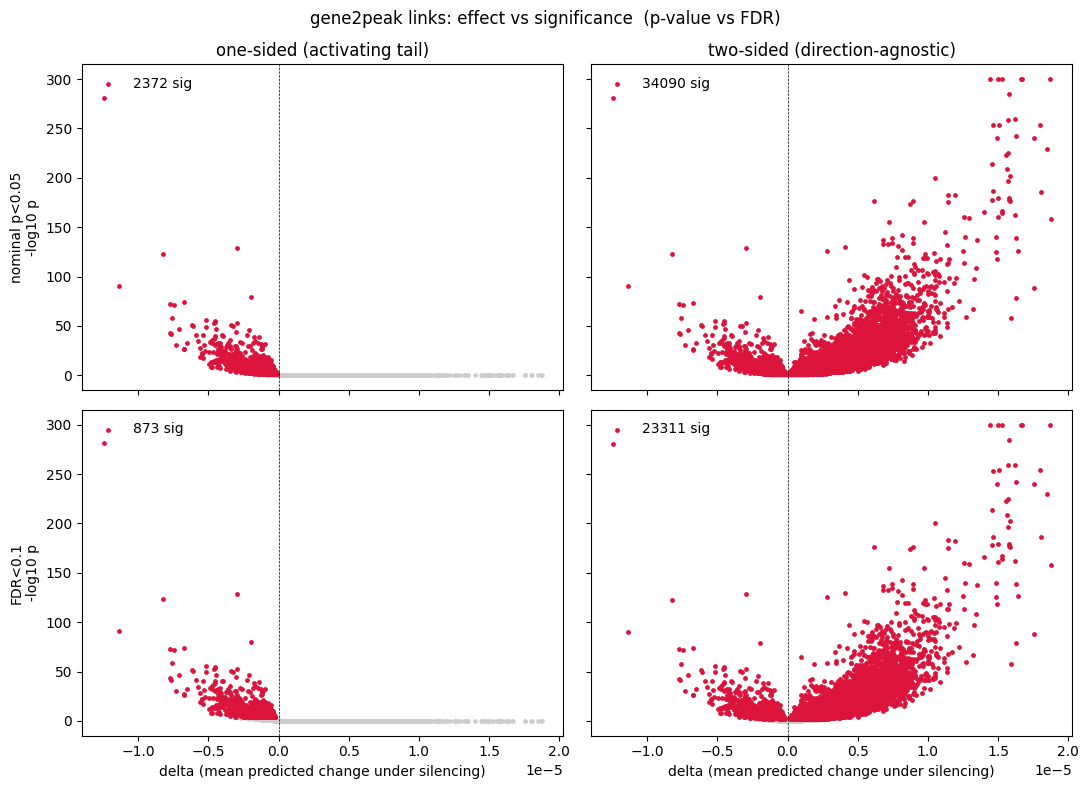

In [9]:
import numpy as np, matplotlib.pyplot as plt

one_p = df['score']
two_p = -np.log10(df['twosided_pvalue'].clip(lower=1e-300))
rows = [('nominal p<0.05', df['pvalue'] < 0.05, df['twosided_pvalue'] < 0.05),
        ('FDR<0.1',        df['fdr'] < 0.1,      df['twosided_fdr'] < 0.1)]
cols = [('one-sided (activating tail)', one_p), ('two-sided (direction-agnostic)', two_p)]
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
for i, (rlab, sig1, sig2) in enumerate(rows):
    for j, (clab, y) in enumerate(cols):
        ax = axes[i, j]; sig = sig1 if j == 0 else sig2
        ax.scatter(df.loc[~sig, 'delta'], y[~sig], s=5, c='0.8', rasterized=True)
        ax.scatter(df.loc[sig, 'delta'],  y[sig],  s=6, c='crimson', rasterized=True, label=f'{int(sig.sum())} sig')
        ax.axvline(0, color='k', lw=0.5, ls='--'); ax.legend(frameon=False, loc='upper left')
        if i == 0: ax.set_title(clab)
        if j == 0: ax.set_ylabel(f'{rlab}\n-log10 p')
        if i == 1: ax.set_xlabel('delta (mean predicted change under silencing)')
fig.suptitle('gene2peak links: effect vs significance  (p-value vs FDR)')
plt.tight_layout(); plt.show()

The extra positive-`delta` hits in the two-sided panel are mostly softmax renormalization (mass redistributes when a feature is silenced), not real repression — hence one-sided is the default.

## Step 7 — Locus view of a marker gene

Candidate peaks of a CD14 monocyte marker (auto-picked as the best-linked marker present) by distance from its TSS vs `score`. Star = top peak.

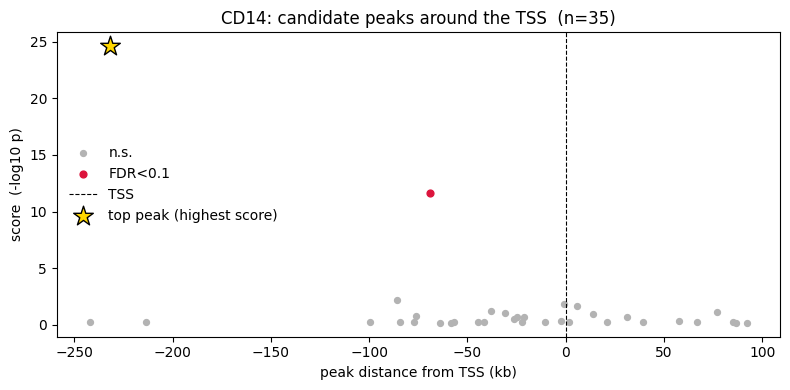

In [10]:
tss = io.tss_from_gtf(GTF).set_index('gene')['tss']
markers = ['CTSS', 'S100A8', 'S100A9', 'S100A12', 'S100A6', 'LYZ', 'FCN1', 'VCAN', 'FCGR3A', 'CD14']
present = [m for m in markers if m in set(df['gene']) and m in tss.index]
feature_gene = (max(present, key=lambda m: df.loc[df['gene'] == m, 'score'].max())
                if present else df.loc[df['score'].idxmax(), 'gene'])
g = df[df['gene'] == feature_gene].copy()
g['peak_center'] = (g['peak_start'] + g['peak_end']) / 2
g['kb_from_tss'] = (g['peak_center'] - tss[feature_gene]) / 1e3

sig_g = g['fdr'] < 0.1
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(g.loc[~sig_g, 'kb_from_tss'], g.loc[~sig_g, 'score'], s=18, c='0.7', label='n.s.')
ax.scatter(g.loc[sig_g,  'kb_from_tss'], g.loc[sig_g,  'score'], s=24, c='crimson', label='FDR<0.1')
ax.axvline(0, color='k', lw=0.8, ls='--', label='TSS')
top = g.loc[g['score'].idxmax()]
ax.scatter([top['kb_from_tss']], [top['score']], marker='*', s=220, c='gold', edgecolor='k',
           zorder=5, label='top peak (highest score)')
ax.set_xlabel('peak distance from TSS (kb)'); ax.set_ylabel('score  (-log10 p)')
ax.set_title(f'{feature_gene}: candidate peaks around the TSS  (n={len(g)})')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## Step 8 — Per-cell heatmap for the marker gene

`compute_cell_deltas` gives the per-cell delta for one gene. Rows are the cells where the gene is **detected** (silencing an unexpressed gene gives no signal) — this matches multiDGD's own `gene2peak`, which restricts to expressing cells. multiDGD's tutorial orders rows by cell type; with a single cell type here we instead order cells by their response at the top (starred) peak. Columns are the gene's candidate peaks by position.

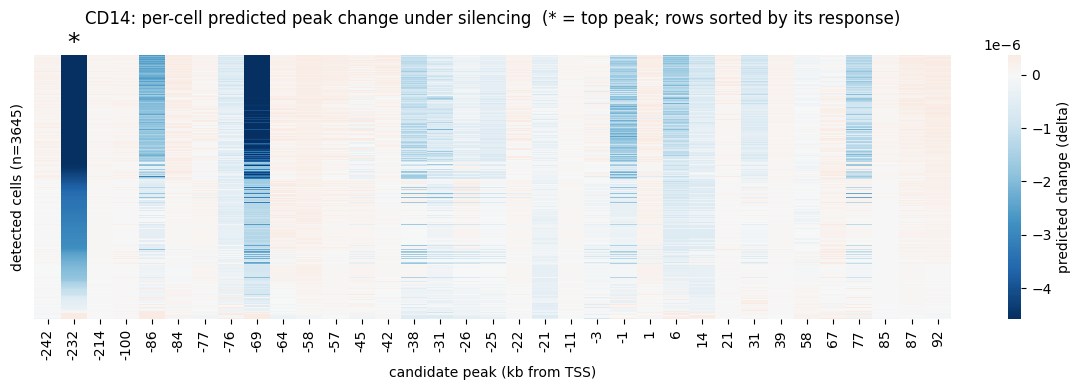

In [11]:
tg = df[df['gene'] == feature_gene].sort_values('peak_start')
target_peaks = tg['peak'].tolist()
resp_cols = [peak_col[p] for p in target_peaks]

delta_cells, cell_idx = compute_cell_deltas(
    model, feature_gene, silenced_index, resp_cols, 'gene2peak', cell_batch=8192)

top_peak = tg.loc[tg['score'].idxmax(), 'peak']
star_col = target_peaks.index(top_peak)
order = np.argsort(delta_cells[:, star_col])          # order cells by response at the top peak
col_kb = [f'{(c - tss[feature_gene]) / 1e3:.0f}' for c in ((tg['peak_start'] + tg['peak_end']) // 2)]
hm = pd.DataFrame(delta_cells[order], columns=col_kb)

fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(hm, cmap='RdBu_r', center=0, robust=True, yticklabels=False,
            cbar_kws={'label': 'predicted change (delta)'}, ax=ax)
ax.annotate('*', xy=(star_col + 0.5, 0), xytext=(star_col + 0.5, -0.4),
            ha='center', va='bottom', fontsize=18)
ax.set_title(f'{feature_gene}: per-cell predicted peak change under silencing  (* = top peak; rows sorted by its response)', pad=22)
ax.set_xlabel('candidate peak (kb from TSS)'); ax.set_ylabel(f'detected cells (n={len(cell_idx)})')
plt.tight_layout(); plt.show()

For the matched null or the other direction, re-run `run_genomewide.sh` with `--bg matched` or `--direction peak2gene`. Column definitions: [../README.md](../README.md#output).